# 03 — Our Solution: 30 Simulated Qubits in a World-Model Setup

**System:** classical trunk (sprint loop: small FNO; headline: frozen Ant Group **LingBot-World v2 14B** causal-fast, weights on disk) + a quantum bottleneck whose analog Hamiltonian **adapts to the simulation state**: pooled latent -> per-qubit detunings + trainable 2D atom geometry -> Rydberg evolution -> <Z> readout -> zero-init gated residual.

**30 simulated qubits** = 3 independent 10-qubit registers (blockade-decoupled patches of one 30-atom array — hardware-honest, trainable today). Ladder: entangled 30q via MPS-chi training next; exact 30q statevector is inference-only (8.6 GB).

Hypotheses under test (see 08-scoreboard.md): **H1** analog quantum blocks improve physical simulation; **H2** qubits improve large multimodal world models.

In [1]:
import sys, pathlib, glob, re, warnings
warnings.filterwarnings('ignore')
ROOT = pathlib.Path().resolve().parent
sys.path.insert(0, str(ROOT / 'paper'))
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
DEVICE = 'cpu'   # GPU reserved for the sprint queue; flip when free
torch.manual_seed(0)


## Mechanism, visibly
The trainable atom geometry and the blockade interaction it induces — this is the object that would compile onto neutral-atom hardware (Pulser export).

one register params: 2108
3x10q (30 simulated qubits) params: 6324


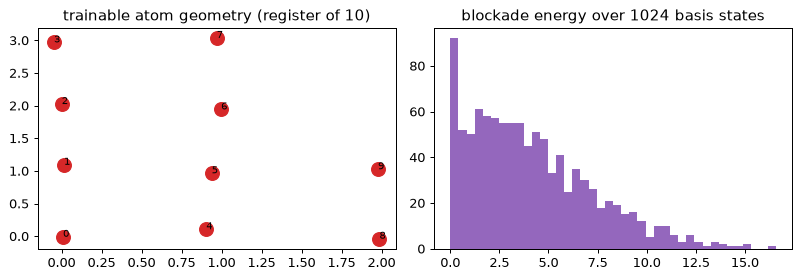

In [2]:
from qlayer import QuantumBlock, MultiRegister
qb = QuantumBlock(d_in=24, n=10, layers=4, ansatz='rydberg')
print('one register params:', sum(p.numel() for p in qb.parameters()))
mr = MultiRegister(24, 10, 3, 4, 'rydberg')
print('3x10q (30 simulated qubits) params:', sum(p.numel() for p in mr.parameters()))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
pos = qb.pos.detach().numpy()
ax[0].scatter(pos[:, 0], pos[:, 1], s=120, c='tab:red')
for i, p in enumerate(pos): ax[0].annotate(str(i), p, fontsize=8)
ax[0].set_title('trainable atom geometry (register of 10)')
eng = qb._blockade_energy().detach().numpy()
ax[1].hist(eng, bins=40, color='tab:purple')
ax[1].set_title('blockade energy over 1024 basis states')
plt.tight_layout(); plt.show()

## The block adapts to the input state
Two different pooled latents produce different detuning patterns, hence different analog evolutions and readouts — input-conditioned analog simulation in one figure.

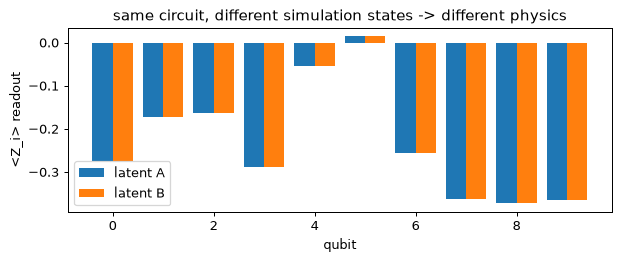

In [3]:
h_a = torch.randn(1, 24); h_b = torch.randn(1, 24)
za = qb(h_a).detach().numpy()[0]; zb = qb(h_b).detach().numpy()[0]
x = np.arange(10)
plt.figure(figsize=(7, 3))
plt.bar(x - .2, za, .4, label='latent A'); plt.bar(x + .2, zb, .4, label='latent B')
plt.xlabel('qubit'); plt.ylabel('<Z_i> readout'); plt.legend()
plt.title('same circuit, different simulation states -> different physics')
plt.tight_layout(); plt.show()

## Live hypothesis verdicts (re-run this section after every round)

In [4]:
from log_notebook import parse_log
def results_frame():
    rows = []
    for f in sorted(glob.glob(str(ROOT / 'runs' / 'round*_*.log'))):
        name = pathlib.Path(f).stem
        rnd, rest = name.split('_', 1)
        m = re.match(r'(.+?)_s(\d+)$', rest)
        variant, seed = (m.group(1), int(m.group(2))) if m else (rest, 1337)
        d = parse_log(f)
        if d['crashed']:
            continue
        rows.append(dict(round=rnd, variant=variant, seed=seed,
                         v1=float(d['val_vrmse_1']), v8=float(d['val_vrmse_8']),
                         steps=int(d['num_steps']), params=int(d['num_params'])))
    return pd.DataFrame(rows)
df = results_frame()
r3 = df[df['round'] == 'round3']
if len(r3) == 0:
    print('round 3 still running — showing rounds 1-2 evidence')
else:
    piv = r3.pivot_table(index='variant', columns='seed', values='v8')
    piv['mean'] = piv.mean(axis=1); piv['std'] = piv.std(axis=1)
    print(piv.round(3).to_string())
    from scipy.stats import wilcoxon
    for q in ['mr30hea', 'mr30ryd']:
        for c in ['none', 'mlp30']:
            a = r3[r3.variant == q].sort_values('seed')['v8'].values
            b = r3[r3.variant == c].sort_values('seed')['v8'].values
            n = min(len(a), len(b))
            if n >= 2:
                win = (a[:n] < b[:n]).all()
                print(f'{q} vs {c}: seeds={n}, all-seeds-win={win}, '
                      f'mean diff={np.mean(a[:n]-b[:n]):+.3f}')
print()
print('NOTE: n=3 paired Wilcoxon cannot reach p<0.05; the protocol')
print('upgrade (round 4) logs per-regime VRMSE -> 9 paired points.')

seed      1337   1338   1339   mean    std
variant                                   
mlp30    0.987  1.421  0.960  1.123  0.211
mr30hea  0.906  1.268  1.017  1.063  0.152
mr30ryd  1.086  0.942  0.836  0.955  0.102
none     1.344  0.926  1.063  1.111  0.174


mr30hea vs none: seeds=3, all-seeds-win=False, mean diff=-0.047
mr30hea vs mlp30: seeds=3, all-seeds-win=False, mean diff=-0.059
mr30ryd vs none: seeds=3, all-seeds-win=False, mean diff=-0.156
mr30ryd vs mlp30: seeds=3, all-seeds-win=False, mean diff=-0.168

NOTE: n=3 paired Wilcoxon cannot reach p<0.05; the protocol
upgrade (round 4) logs per-regime VRMSE -> 9 paired points.


## Problems log (live)
1. **Run variance ~0.17 v8** between math-equivalent runs -> multi-seed everything; per-regime eval to get 9 paired points per comparison.
2. **hea qubit scaling non-monotone** at fixed steps (12q>16q) — consistent with bottleneck-capacity vs optimization tradeoff; the analog ansatz scaled positively (12->16). 30q multi-register decides.
3. **Entangled 30q untrainable** on statevector (8.6 GB, minutes/grad) -> product-register now, MPS-chi next (CUDA-Q tensornet-mps verified).
4. **Sprint protocol != official protocol** (1-frame vs 4-frame history, downsampled, valid vs test) -> H1d trainer closes the gap.
5. cudaq/torch cannot share a process (LLVM clash) -> CUDA-Q referee runs subprocess-only.

## Impact analysis
- H1 pass -> first quantum-hybrid entry on a public PDE benchmark with matched controls (literature has zero; closest attempt lost to its own control).
- H1 fail -> equally publishable negative with the strongest controls to date (2607.09905 bar).
- H2 pass -> first quantum adapter in a frozen video world model (slot verified open as of 2026-07-26).
- Either way: every number reproduces on one 126 GB desktop.

## Phase B (live) — beating CNextU-net from its own checkpoint

**Goal (user):** one-step TEST mean-VRMSE < **0.1934** (our reproduction of the official checkpoint over 873 windows; published 0.1956), paired per-window Wilcoxon p<0.05.

Strategy: the quantum bottleneck wraps the U-Net **neck** of the official checkpoint with a zero-init gate — at initialization the hybrid IS the published SOTA model bit-for-bit; fine-tuning arms (vanilla continuation / +30q Rydberg / +matched MLP) start from the identical point and identical valid score (0.1865).

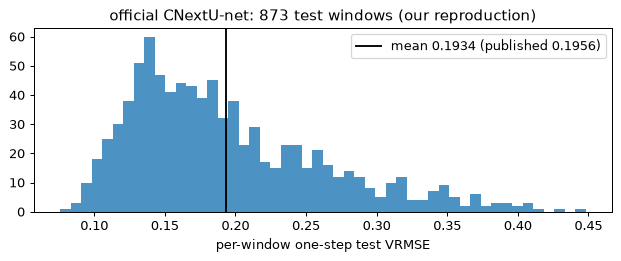

mean 0.1934  median 0.1772  std 0.0690  n=873


In [5]:
import csv as _csv
anchor = np.array([float(r['vrmse']) for r in _csv.DictReader(
    open(ROOT / 'runs/eval_official_cnext.csv'))])
fig, ax = plt.subplots(1, 1, figsize=(7, 3))
ax.hist(anchor, bins=50, color='tab:blue', alpha=.8)
ax.axvline(anchor.mean(), c='k', lw=1.5,
           label=f'mean {anchor.mean():.4f} (published 0.1956)')
ax.set_xlabel('per-window one-step test VRMSE'); ax.legend()
ax.set_title('official CNextU-net: 873 test windows (our reproduction)')
plt.tight_layout(); plt.show()
print(f'mean {anchor.mean():.4f}  median {np.median(anchor):.4f}  '
      f'std {anchor.std():.4f}  n={len(anchor)}')

### Statistical power of the paired test
Fine-tuned siblings of the same checkpoint are highly correlated per-window, so the paired test detects tiny real shifts. Minimal detectable mean shift (alpha=0.05, power 0.8) under assumed sibling correlations rho:

In [6]:
for rho in (0.8, 0.9, 0.95, 0.99):
    sd = anchor.std() * np.sqrt(2 * (1 - rho))
    print(f'rho={rho:.2f}: detectable shift ~ '
          f'{2.8 * sd / np.sqrt(len(anchor)):.4f} VRMSE')
print('=> even ~0.001-0.005 improvements are provable at n=873;')
print('   the goal does not require a miracle effect size.')

rho=0.80: detectable shift ~ 0.0041 VRMSE
rho=0.90: detectable shift ~ 0.0029 VRMSE
rho=0.95: detectable shift ~ 0.0021 VRMSE
rho=0.99: detectable shift ~ 0.0009 VRMSE
=> even ~0.001-0.005 improvements are provable at n=873;
   the goal does not require a miracle effect size.


### Live fine-tune tracker (re-run this cell during any Phase-B run)

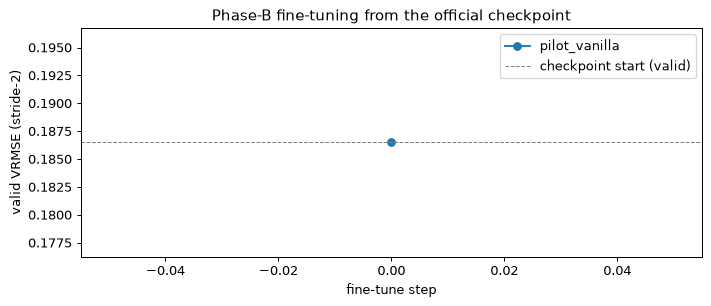

pilot_vanilla            best valid 0.1865


In [7]:
runs_dir = ROOT / 'runs/phase_b'
fig, ax = plt.subplots(figsize=(8, 3.5))
best = {}
for f in sorted(glob.glob(str(runs_dir / '*.log'))):
    txt = open(f).read()
    pts = [(int(m.group(1)), float(m.group(2))) for m in
           re.finditer(r'val_check step=(\d+) vrmse=([\d.]+)', txt)]
    if pts:
        s, v = zip(*pts)
        name = pathlib.Path(f).stem
        ax.plot(s, v, marker='o', label=name)
        best[name] = min(v)
if best:
    ax.axhline(0.1865, ls='--', c='gray', lw=.8, label='checkpoint start (valid)')
    ax.set_xlabel('fine-tune step'); ax.set_ylabel('valid VRMSE (stride-2)')
    ax.set_title('Phase-B fine-tuning from the official checkpoint'); ax.legend()
    plt.tight_layout(); plt.show()
    for k, v in sorted(best.items(), key=lambda x: x[1]):
        print(f'{k:24s} best valid {v:.4f}')
else:
    print('no val_check lines yet — runs starting')

## Continue here (lab bench)
Flip `RUN_QUICK=True` when the GPU is free to train any variant for a short budget and append to the ledger; then re-run the verdict cell above.

In [8]:
RUN_QUICK = False
VARIANT, SEED, BUDGET_S = 'mr30ryd', 1340, 120
if RUN_QUICK:
    import subprocess
    log = ROOT / 'runs' / f'lab_{VARIANT}_s{SEED}.log'
    subprocess.run(['uv', 'run', 'paper/train.py', VARIANT, str(SEED),
                    str(BUDGET_S)], cwd=ROOT, stdout=open(log, 'w'),
                   stderr=subprocess.STDOUT)
    print(open(log).read()[-400:])
else:
    print('GPU busy with sprint queue — skipped (set RUN_QUICK=True later)')

GPU busy with sprint queue — skipped (set RUN_QUICK=True later)
